[Open in Colab](https://colab.research.google.com/github/yueliosu/yueliphd.net/blob/main/tutorials/coms930/bert-supervised-learning.ipynb){.btn .btn-primary .btn-sm} [Download notebook (.ipynb)](bert-supervised-learning.ipynb){.btn .btn-outline-primary .btn-sm}

::: {.callout-note appearance="simple"}
Downloads its data from the UCSD Book Graph. Choose a GPU runtime in Colab (Runtime → Change runtime type).
:::

Yue Li, Ph.D.
Assistant Professor
Department of Communication Studies

*Adapted from the AI for Humanists tutorial "Training and Fine-Tuning BERT for Classification" by Maria Antoniak, Melanie Walsh, and David Mimno ([original tutorial](https://melaniewalsh.github.io/Intro-Cultural-Analytics/08-LLMs-and-AI/03-Text-Classification.html)).*
<br></br>

This notebook will demonstrate how users can train and fine-tune a BERT model for classification with the popular HuggingFace `transformers` Python library.

We will fine-tune a BERT model on Goodreads reviews from the [UCSD Book Graph](https://sites.google.com/eng.ucsd.edu/ucsdbookgraph/reviews?authuser=0) with the goal of predicting the genre of the book being reviewed. The genres include:

- poetry
- comics & graphic
- fantasy & paranormal
- history & biography
- mystery, thriller, & crime
- romance
- young adult  

**Basic steps involved in using BERT and HuggingFace:**

1. Divide your data into training and test sets.
2. Encode your data into a format BERT will understand.
3. Combine your data and labels into dataset objects.
4. Load the pre-trained BERT model.
5. Fine-tune the model using your training data.
6. Predict new labels and evaluate performance on your test data.



<br><br>

## **Import necessary Python libraries and modules**

To use the HuggingFace [`transformers` Python library](https://huggingface.co/transformers/installation.html), we will install it with `pip`. Remember that when you run a command in a Jupyter notebook that starts with `!`, that command will run on the command line (not in Python). Because we're working in Colab, you'll need to reinstall any new packages everytime you restart the kernel.

In [ ]:
!pip3 install transformers
!pip install -U transformers accelerate

Next, we will import necessary Python libraries and modules. These include as `gdown`, for downloading large files from Google Drive (where we will get our UCSD Goodreads reviews), as well as scikit-learn (`sklearn`) and PyTorch (`torch`), for various machine learning tools.

In [ ]:
from collections import defaultdict
import gdown
import gzip
import json
import random
import pickle

import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import torch
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification
from transformers import Trainer, TrainingArguments

%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import ticker
sns.set(style='ticks', font_scale=1.2)

<br><br>

## **Set parameters and file paths**

In [ ]:
# This is the name of the BERT model that we want to use.
# We're using DistilBERT to save space (it's a distilled version of the full BERT model),
# and we're going to use the cased (vs uncased) version.
model_name = 'distilbert-base-cased'

# This is the name of the program management system for NVIDIA GPUs. We're going to send our code here.
device_name = 'cuda'

# This is the maximum number of tokens in any document sent to BERT.
max_length = 512

# This is the name of the directory where we'll save our model. You can name it whatever you want.
cached_model_directory_name = 'distilbert-reviews-genres'

<br><br>

## **Load and sample Goodreads data**

In this cell, we create a Python dictionary with each genre and the link to the corresponding UCSD Goodreads review data for that genre on Google Drive.

*If you manually click on any of the URLs, you will be able to download the data for that genre. For example, here's the link for poetry: https://drive.google.com/uc?id=1FVD3LxJXRc5GrKm97LehLgVGbRfF9TyO*

In [ ]:
# This is where our target data is hosted on the web. You only need these paths for the book review dataset.

genre_url_dict = {'poetry':                 'https://drive.google.com/uc?id=1mWDEbd5i4kXqYHHWcxBQ0qQx-dKfFWik',
                  'children':               'https://drive.google.com/uc?id=18aCsiGeNq9kxfDHyr1A-oODoeIAtpvV6',
                  'comics_graphic':         'https://drive.google.com/uc?id=1kHhmcO3Hz2cIhxIFK6aRvTZ1TdrvLTZS',
                  'fantasy_paranormal':     'https://drive.google.com/uc?id=1S749kMNmQZmOq9XEKg7Xc1YL_vEH0lfA',
                  'history_biography':      'https://drive.google.com/uc?id=1WmsB0nKX2bKgzJJJ2XSea_3QfV5umeqW',
                  'mystery_thriller_crime': 'https://drive.google.com/uc?id=1VXeXevB2PW6p9esgQTdwMeoHcUMIhyUY',
                  'romance':                'https://drive.google.com/uc?id=18TlvpA377c2Dzhh9pzW1eaMoSpfTNqDt',
                  'young_adult':            'https://drive.google.com/uc?id=1-oNsvebACiPWwxsE-W0Y4ehYBjyLvieO'}

Next we loop through this dictionary and use `gdown` to download the Goodreads review data for each genre from Google Drive. This can take a few moments to run.

In [ ]:
for _genre, _url in genre_url_dict.items():
  gdown.download(_url, _genre + '.json.gz', quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1mWDEbd5i4kXqYHHWcxBQ0qQx-dKfFWik
From (redirected): https://drive.google.com/uc?id=1mWDEbd5i4kXqYHHWcxBQ0qQx-dKfFWik&confirm=t&uuid=cd9ce130-b7a0-4c4a-9085-bc2bb27c76d3
To: /content/poetry.json.gz
100%|██████████| 49.4M/49.4M [00:02<00:00, 24.1MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=18aCsiGeNq9kxfDHyr1A-oODoeIAtpvV6
From (redirected): https://drive.google.com/uc?id=18aCsiGeNq9kxfDHyr1A-oODoeIAtpvV6&confirm=t&uuid=bb801471-f659-4d0c-8198-511b2900cee9
To: /content/children.json.gz
100%|██████████| 172M/172M [00:03<00:00, 43.0MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1kHhmcO3Hz2cIhxIFK6aRvTZ1TdrvLTZS
From (redirected): https://drive.google.com/uc?id=1kHhmcO3Hz2cIhxIFK6aRvTZ1TdrvLTZS&confirm=t&uuid=8392abe4-e146-4f65-beb3-12c162001a6f
To: /content/comics_graphic.json.gz
100%|██████████| 147M/147M [00:02<00:00, 54.0MB/s]
Downloading...
From (original): https://drive.google

If you click the file browser icon in the left-hand side bar, you should see that these files have now been download.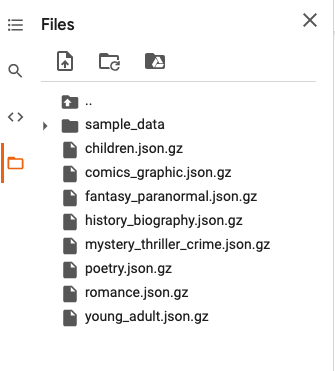

Next we create a function `load_reviews()`, which will use `gzip` to unzip the downloaded Goodreads review JSON files and `json` to load the JSON files once they're unzipped.

In [ ]:
def load_reviews(file_name,
                 head=None):

    reviews = []
    count = 0

    with gzip.open(file_name) as file:
        for line in file:

            d = json.loads(line)
            count += 1

            _book_id = d['book_id']

            reviews.append(d['review_text'])

            # Break if we reach the Nth line
            if (head is not None) and (count > head):
                break

    return reviews

Now we apply the `load_reviews()` function. For each genre, we load and unzip the corresponding `.json.gz` file, e.g., `poetry.json.gz`, then we randomly sample 2000 Goodreads reviews and make a dictionary `genre_reviews_dict` of all these reviews.

In [ ]:
genres = ['poetry', 'children', 'comics_graphic', 'fantasy_paranormal', 'history_biography', 'mystery_thriller_crime', 'romance', 'young_adult']
genre_reviews_dict = {}

for _genre in genres:
  print('Loading ' + _genre + '.json.gz')
  _reviews = load_reviews(_genre + '.json.gz')
  genre_reviews_dict[_genre] = random.sample(_reviews, 2000)

Loading poetry.json.gz
Loading children.json.gz
Loading comics_graphic.json.gz
Loading fantasy_paranormal.json.gz
Loading history_biography.json.gz
Loading mystery_thriller_crime.json.gz
Loading romance.json.gz
Loading young_adult.json.gz


Let's preview a couple of the key-value pairs in `genre_reviews_dict`

In [ ]:
for _genre, _reviews in genre_reviews_dict.items():
  print('===========================')
  print(_genre)
  print('===========================')
  print(random.sample(_reviews, 1)[0])
  print()

poetry
So genius! One of those - why didn't I think of this - kinds of things...

children
A 
 SM

comics_graphic
Super sweet! I love Ito and Mako's developing relationship!

fantasy_paranormal


history_biography
Interesting theory, and I really like Graham Hancock's writing style.

mystery_thriller_crime
A short story that starts a new series by Janet Evanovich. Like Stephanie Plum, the FBI agent Kate O'Hare likes junk food and is chasing after a hot man. The twist is that this hot man is criminal. I'll catch the rest of the series on audiobook, because it is fluffy and hopefully entertain me.

romance
Hiaaahh... 
 *Spektakuler* 
 Waktu suami pulang ke Indo, saya minta oleh2 buku Tere Liye..iyah...bagi saya bukunya sudah seperti kacang Bali, teh Tong Tji atau emping manis Ny Shiok..makanan yg saya rindukan di rantau dan tidak bisa didapat cuma di Indonesia. 
 Buku ini begitu saya baca, langsung..hmm..ini kan Christmas Carol-nya Charles Dickens? Kok gak orisinil? Percis kejadiannya di

Here we use `pickle` to save this Python dictionary to a `.pickle` file so we can easily load it later.

*The `pickle` module allows you to save and load Python objects like lists and dictionaries.*

In [ ]:
pickle.dump(genre_reviews_dict, open('genre_reviews_dict.pickle', 'wb'))
# genre_reviews_dict = pickle.load(open('genre_reviews_dict.pickle', 'rb'))

<br><br>

## **Split the data into training and test sets**

When training a machine learning model, it is necessary to split your training data into two parts: a **training** set and a **test** set.

We will train our BERT model on the "training" set of Goodreads reviews and then we will evaluate how well it is performing by running it on the "test" set of Goodreads reviews that the model has never seen before.

Normally, to tune the hyperparameters, you should also create a "validation" set for tuning, and only use the "test" set once, at the end of all tuning. For simplicity, in this tutorial, we will only using a training and test set.

In [ ]:
train_texts = []
train_labels = []

test_texts = []
test_labels = []

for _genre, _reviews in genre_reviews_dict.items():

  _reviews = random.sample(_reviews, 1000) # Use a very small set as an example.

  for _review in _reviews[:800]:
    train_texts.append(_review)
    train_labels.append(_genre)
  for _review in _reviews[800:]:
    test_texts.append(_review)
    test_labels.append(_genre)

Show how many Goodreads reviews and labels we have in each category: 6400 training reviews, 6400 training labels (genres), 1600 test reviews, 1600 test labels (genre)

In [ ]:
len(train_texts), len(train_labels), len(test_texts), len(test_labels)

(6400, 6400, 1600, 1600)

Here's an example of a training label and review:

In [ ]:
train_labels[0], train_texts[0]

('poetry',
 'I don\'t overly enjoy poetry for the most part, but I have to say, I really enjoy Allen Ginsberg\'s writing. \n I had previously read "Howl" and "A Supermarket in California" which I very much enjoyed. The other poems, being new to me, I thoroughly enjoyed. \n Ginsberg has a very interesting writing style that is very vivid. I love how he speaks directly to his fellow poets in some of his poems. In writing them in, he is giving them an even greater form of immortality. \n I enjoyed the poem "America." It\'s asking the citizens of America what the war is worth, but America is also asking things of him that he wouldn\'t be able to live up to. He questions his own writing in this as well. \n Ginsberg has a very musical beat to his poems that makes you have to keep reading. It pulls you along, especially when you read it out loud. \n Overall, I very much enjoyed this little book of poems.')

<br><br>

## **Run a baseline model (logistic regression)**

Here we train and evaluate a simple TF-IDF baseline model using logistic regression.

We find better-than-random performance, even for a very small dataset. We'll see whether BERT can beat this good baseline!

In [ ]:
vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(train_texts)
X_test = vectorizer.transform(test_texts)

We train a logistic regression model from scikit-learn on the Goodreads training data, and then we use the trained model to make predictions on our Goodreads review test set.

In [ ]:
model = LogisticRegression(max_iter=1000).fit(X_train, train_labels)
predictions = model.predict(X_test)

We can use scikit-learn's `classification_report` function to evaluate how well the logistic regression model's predictions match up with the true labels for the Goodreads reviews.

Importantly, we can see that our average scores are above random performance (we have 8 classes, so random performance would be ~0.2).

In [ ]:
print(classification_report(test_labels, predictions))

                        precision    recall  f1-score   support

              children       0.58      0.61      0.60       200
        comics_graphic       0.53      0.57      0.55       200
    fantasy_paranormal       0.38      0.27      0.32       200
     history_biography       0.46      0.45      0.45       200
mystery_thriller_crime       0.58      0.51      0.54       200
                poetry       0.59      0.77      0.67       200
               romance       0.48      0.51      0.49       200
           young_adult       0.40      0.38      0.39       200

              accuracy                           0.51      1600
             macro avg       0.50      0.51      0.50      1600
          weighted avg       0.50      0.51      0.50      1600



<br><br>

## **Encode data for BERT**

We're going to transform our texts and labels into a format that BERT (via Huggingface and PyTorch) will understand. This is called *encoding* the data.

Here are the steps we need to follow:

1. The labels&mdash;in this case, Goodreads genres&mdash;need to be turned into integers rather than strings.

2. The texts&mdash;in this case, Goodreads reviews&mdash;need to be truncated if they're more than 512 tokens or padded if they're fewer than 512 tokens. The tokens, or words in the texts, also need to be separated into "word pieces" and matched to their embedding vectors.

3. We need to add special tokens to help BERT:

| BERT special token | Explanation |
| --------------| ---------|
| [CLS] | Start token of every document. |
| [SEP] | Separator between each sentence |
| [PAD] | Padding at the end of the document as many times as necessary, up to 512 tokens |
|  &#35;&#35; | Start of a "word piece" |




Here we will load `DistilBertTokenizerFast` from the HuggingFace library, which will do all the work of encoding the texts for us. The `tokenizer()` will break word tokens into word pieces, truncate to 512 tokens, and add padding and special BERT tokens.

In [ ]:
tokenizer = DistilBertTokenizerFast.from_pretrained(model_name) # The model_name needs to match our pre-trained model.

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Here we will create a map of our labels, or Goodreads genres, to integer keys. We take the unique labels, and then we make a dictionary that associates each label/tag with an integer.

**Note:** HuggingFace documentation sometimes refers to "labels" as "tags" but these are the same thing. We use "labels" throughout this notebook for clarity.

In [ ]:
unique_labels = set(label for label in train_labels)
label2id = {label: id for id, label in enumerate(unique_labels)}
id2label = {id: label for label, id in label2id.items()}

In [ ]:
label2id.keys()

dict_keys(['history_biography', 'romance', 'mystery_thriller_crime', 'comics_graphic', 'children', 'young_adult', 'poetry', 'fantasy_paranormal'])

In [ ]:
id2label.keys()

dict_keys([0, 1, 2, 3, 4, 5, 6, 7])

Now let's encode our texts and labels!

In [ ]:
train_encodings = tokenizer(train_texts, truncation=True, padding=True, max_length=max_length)
test_encodings  = tokenizer(test_texts, truncation=True, padding=True, max_length=max_length)

train_labels_encoded = [label2id[y] for y in train_labels]
test_labels_encoded  = [label2id[y] for y in test_labels]

**Examine a Goodreads review in the training set after encoding**

In [ ]:
' '.join(train_encodings[0].tokens[0:100])

'[CLS] I don \' t overly enjoy poetry for the most part , but I have to say , I really enjoy Allen G ##ins ##berg \' s writing . I had previously read " How ##l " and " A Super ##market in California " which I very much enjoyed . The other poems , being new to me , I thoroughly enjoyed . G ##ins ##berg has a very interesting writing style that is very vivid . I love how he speaks directly to his fellow poets in some of his poems . In writing them in ,'

**Examine a Goodreads review in the test set after encoding**

In [ ]:
' '.join(test_encodings[0].tokens[0:100])

"[CLS] While a fan of his work and its pen ##sive and per ##verse streaks , this one didn ' t get my whole love - yes , I know kids sent in the material and he chose from that , but the bit about the turtle falling down the stairs ( hello dead turtle or suffering turtle with cracked shell ) annoyed me . I can just imagine some kid ch ##ucking his turtle down the stairs now with all the life im ##itate ##s art and kids take things much more literally than one would think . ."

**Examine the training labels after encoding**

In [ ]:
set(train_labels_encoded)

{0, 1, 2, 3, 4, 5, 6, 7}

**Examine the test labels after encoding**

In [ ]:
set(test_labels_encoded)

{0, 1, 2, 3, 4, 5, 6, 7}

<br><br>

## **Make a custom Torch dataset**

Here we combine the encoded labels and texts into dataset objects. We use the custom Torch `MyDataSet` class to make a `train_dataset` object from  the `train_encodings` and `train_labels_encoded`. We also make a `test_dataset` object from `test_encodings`, and `test_labels_encoded`.

In [ ]:
class MyDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

In [ ]:
train_dataset = MyDataset(train_encodings, train_labels_encoded)
test_dataset = MyDataset(test_encodings, test_labels_encoded)

**Examine a Goodreads review in the Torch `training_dataset` after encoding**

In [ ]:
' '.join(train_dataset.encodings[0].tokens[0:100])

'[CLS] I don \' t overly enjoy poetry for the most part , but I have to say , I really enjoy Allen G ##ins ##berg \' s writing . I had previously read " How ##l " and " A Super ##market in California " which I very much enjoyed . The other poems , being new to me , I thoroughly enjoyed . G ##ins ##berg has a very interesting writing style that is very vivid . I love how he speaks directly to his fellow poets in some of his poems . In writing them in ,'

**Examine a Goodreads review in the Torch `test_dataset` after encoding**

In [ ]:
' '.join(test_dataset.encodings[1].tokens[0:100])

'[CLS] " S ##yk ##sy , van ##ha a ##jo ##mie ##s , k ##use ##mass ##a vast ##en t ##u ##ult ##a j ##a m ##u ##uta ##ma on ##nell ##inen , j ##oh ##on ha ##nen par ##ske ##ens ##a o ##su ##vat la ##apa ##lla ##an le ##vi ##tte ##lem ##ass ##a ka ##sia ##an . S ##yk ##sy , se ##n il ##mee ##t , k ##un ta ##iva ##an u ##rk ##u ##ja las ##ket ##aan al ##as j ##a ve ##det las ##kos ##tu ##vat j ##ait ##a var ##ten . Hal ##us ##in'

<br><br>

## **Load pre-trained BERT model**

Here we load a pre-trained DistilBERT model and send it to CUDA.

**Note:** If you decide to repeat fine-tuning after already running the following cells, make sure that you re-run this cell to re-load the original pre-trained model before fine-tuning again.

In [ ]:
# The model_name needs to match the name used for the tokenizer above.
model = DistilBertForSequenceClassification.from_pretrained(model_name, num_labels=len(id2label)).to(device_name)

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/263M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


<br><br>

## **Set the BERT fine-tuning parameters**

These are the arguments we'll set in the HuggingFace TrainingArguments objects, which we'll then pass to the HuggingFace Trainer object. There are many more possible arguments, but here we highlight the basics and some common gotchas.

When training your own model, you should search over these parameters to find the best settings for your particular dataset. You should use a held-out set of validation data for this step.

| Parameter | Explanation |
|-----------| ------------|
| num_train_epochs | total number of training epochs (how many times to pass through the entire dataset; too much can cause overfitting) |
| per_device_train_batch_size | batch size per device during training |
| per_device_eval_batch_size |  batch size for evaluation |
|  warmup_steps |  number of warmup steps for learning rate scheduler (set lower because of small dataset size) |
| weight_decay | strength of weight decay (reduces size of weights, like regularization) |
| output_dir | output directory for the fine-tuned model and configuration files |
| logging_dir | directory for storing logs |
| logging_steps | how often to print logging output (so that we can stop training early if the loss isn't going down) |
| evaluation_strategy | evaluate while training so that we can see the accuracy going up |

In [ ]:
training_args = TrainingArguments(
    num_train_epochs=3,              # total number of training epochs
    per_device_train_batch_size=16,  # batch size per device during training
    per_device_eval_batch_size=20,   # batch size for evaluation
    learning_rate=5e-5,              # initial learning rate for Adam optimizer
    warmup_steps=100,                # number of warmup steps for learning rate scheduler (set lower because of small dataset size)
    weight_decay=0.01,               # strength of weight decay
    output_dir='./results',          # output directory
    logging_dir='./logs',            # directory for storing logs
    logging_steps=100,               # number of steps to output logging (set lower because of small dataset size)
    eval_strategy='steps',     # evaluate during fine-tuning so that we can see progress
)

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


<br><br>

## **Fine-tune the BERT model**

First, we define a custom evaluation function that returns the accuracy. You could modify this function to return precision, recall, F1, and/or other metrics.

In [ ]:
def compute_metrics(pred):
  labels = pred.label_ids
  preds = pred.predictions.argmax(-1)
  acc = accuracy_score(labels, preds)
  return {
      'accuracy': acc,
  }

Then we create a HuggingFace `Trainer` object using the `TrainingArguments` object that we created above. We also send our `compute_metrics` function to the `Trainer` object, along with our test and train datasets.

**Note:** This is what we've been aiming for this whole time! All the work of tokenizing, creating datasets, and setting the training arguments was for this cell.

In [ ]:
trainer = Trainer(
    model=model,                         # the instantiated 🤗 Transformers model to be trained
    args=training_args,                  # training arguments, defined above
    train_dataset=train_dataset,         # training dataset
    eval_dataset=test_dataset,           # evaluation dataset (usually a validation set; here we just send our test set)
    compute_metrics=compute_metrics      # our custom evaluation function
)

Time to finally fine-tune!

Be patient; if you've set everything in Colab to use GPUs, then it should take around 15 minutes to run, but if you're running on CPU, it can take hours.

After every 10 steps (as we specified in the TrainingArguments object), the trainer will output the current state of the model, including the training loss, validation ("test") loss, and accuracy (from our `compute_metrics` function).

You should see the loss going down and the accuracy going up. If instead they are staying the same or oscillating, you probably need to change the fine-tuning parameters.

In [ ]:
trainer.train()

Step,Training Loss,Validation Loss,Accuracy
100,2.017328,1.781301,0.323750
200,1.605594,1.445577,0.460625
300,1.469107,1.378239,0.498125
400,1.429352,1.316942,0.511875
500,1.189703,1.354961,0.510000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Step,Training Loss,Validation Loss,Accuracy
100,2.017328,1.781301,0.323750
200,1.605594,1.445577,0.460625
300,1.469107,1.378239,0.498125
400,1.429352,1.316942,0.511875
500,1.189703,1.354961,0.510000
600,1.102996,1.327430,0.509375
700,1.167344,1.300463,0.529375
800,1.083569,1.282925,0.528750
900,0.764858,1.363817,0.532500
1000,0.794149,1.350128,0.531250


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1200, training_loss=1.1768525505065919, metrics={'train_runtime': 1274.2263, 'train_samples_per_second': 15.068, 'train_steps_per_second': 0.942, 'total_flos': 2543646198988800.0, 'train_loss': 1.1768525505065919, 'epoch': 3.0})

<br><br>

## **Save fine-tuned model**

The following cell will save the model and its configuration files to a directory in Colab. To preserve this model for future use, you should download the model to your computer.

In [ ]:
trainer.save_model(cached_model_directory_name)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

(Optional) If you've already fine-tuned and saved the model, you can reload it using the following line. You don't have to run fine-tuning every time you want to evaluate.

In [ ]:
# Run the code below to retrieve the model and the trainer

from transformers import Trainer

model = DistilBertForSequenceClassification.from_pretrained(
    cached_model_directory_name
)

trainer = Trainer(
    model=model,
    args=training_args,
    eval_dataset=test_dataset,
)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

<br><br>

## **Evaluate fine-tuned model**

The following function of the `Trainer` object will run the built-in evaluation, including our `compute_metrics` function.

In [ ]:
trainer.evaluate()

{'eval_loss': 1.359893798828125,
 'eval_accuracy': 0.54,
 'eval_runtime': 27.3224,
 'eval_samples_per_second': 58.56,
 'eval_steps_per_second': 2.928,
 'epoch': 3.0}

But we might want to do more fine-grained analysis of the model, so we extract the predicted labels.

In [ ]:
predicted_results = trainer.predict(test_dataset)

In [ ]:
predicted_results.predictions.shape

(1600, 8)

In [ ]:
predicted_labels = predicted_results.predictions.argmax(-1) # Get the highest probability prediction
predicted_labels = predicted_labels.flatten().tolist()      # Flatten the predictions into a 1D list
predicted_labels = [id2label[l] for l in predicted_labels]  # Convert from integers back to strings for readability

In [ ]:
len(predicted_labels)

1600

In [ ]:
print(classification_report(test_labels,
                            predicted_labels))

                        precision    recall  f1-score   support

              children       0.65      0.69      0.67       200
        comics_graphic       0.68      0.68      0.68       200
    fantasy_paranormal       0.36      0.32      0.34       200
     history_biography       0.58      0.53      0.55       200
mystery_thriller_crime       0.53      0.53      0.53       200
                poetry       0.71      0.76      0.73       200
               romance       0.45      0.50      0.48       200
           young_adult       0.33      0.33      0.33       200

              accuracy                           0.54      1600
             macro avg       0.54      0.54      0.54      1600
          weighted avg       0.54      0.54      0.54      1600



<br><br>

## **Pull out correct and incorrect classifications for examination**

Let's use our predicted labels for some analysis!

Now that we've fine-tuned and pulled out our predicted labels, the BERT part of this tutorial is done. You can now use the predicted labels in the same way you would use any set of predicted labels from any classification model. We'll show some examples here.

First, let's print out some example predictions that were correct.

In [ ]:
for _true_label, _predicted_label, _text in random.sample(list(zip(test_labels, predicted_labels, test_texts)), 20):
  if _true_label == _predicted_label:
    print('LABEL:', _true_label)
    print('REVIEW TEXT:', _text[:100], '...')
    print()

LABEL: children
REVIEW TEXT: There's a name for stories about why things are the way they are, isn't there? Is "Just So Stories"  ...

LABEL: poetry
REVIEW TEXT: Sensual verse. 
 The collection felt a little uneven to me - I found myself not all that into the be ...

LABEL: comics_graphic
REVIEW TEXT: My love for side couples is immense. 
 It's so bad how much I love them. 
 So naturally them having  ...

LABEL: comics_graphic
REVIEW TEXT: Nice, I enjoyed it, the art was cool. Not a fan of the "it's supposed to be about the women but actu ...

LABEL: children
REVIEW TEXT: So cute, I teared up a little in the end. ...

LABEL: romance
REVIEW TEXT: Reviewer: Diane 
 Genre:M/M Contemporary 
 5 Hearts 
 Review: 
 Luther Almond has inherited his gran ...

LABEL: young_adult
REVIEW TEXT: #####5 Nerdy Bad Boy Hashtags##### 
 Whew... I need me an Asher Wright!!!! A tatted up bad boy looki ...

LABEL: mystery_thriller_crime
REVIEW TEXT: Jonathan Hayes brings back disgraced pathologist Edward Jen

Now let's print out some misclassifications.

In [ ]:
for _true_label, _predicted_label, _text in random.sample(list(zip(test_labels, predicted_labels, test_texts)), 20):
  if _true_label != _predicted_label:
    print('TRUE LABEL:', _true_label)
    print('PREDICTED LABEL:', _predicted_label)
    print('REVIEW TEXT:', _text[:100], '...')
    print()

TRUE LABEL: poetry
PREDICTED LABEL: history_biography
REVIEW TEXT: One of my favorites. Definitely one of the best books I've read in the past five years. I'll look fo ...

TRUE LABEL: comics_graphic
PREDICTED LABEL: romance
REVIEW TEXT: Actually a 4.75 not quite a five but I did super enjoy it ...

TRUE LABEL: young_adult
PREDICTED LABEL: romance
REVIEW TEXT: Totally not what I was expecting at all but I still loved it. Such an interesting commentary on teen ...

TRUE LABEL: young_adult
PREDICTED LABEL: fantasy_paranormal
REVIEW TEXT: This is the second book in the Raven Cycle series, and I think it has a very good chance of becoming ...

TRUE LABEL: comics_graphic
PREDICTED LABEL: fantasy_paranormal
REVIEW TEXT: Really different kind of GN. Definitely the type of book you need to reread a couple of times to gra ...

TRUE LABEL: romance
PREDICTED LABEL: mystery_thriller_crime
REVIEW TEXT: Elianna is the revered Mafia Princess, Lucas is the Rufficello Bastard. 
 He knows he should stay

Finally, let's create some heatmaps to examine misclassification patterns. We could use these patterns to think about similarities and differences between genres, according to book reviewers.

In [ ]:
genre_classifications_dict = defaultdict(int)
for _true_label, _predicted_label in zip(test_labels, predicted_labels):
  genre_classifications_dict[(_true_label, _predicted_label)] += 1

dicts_to_plot = []
for (_true_genre, _predicted_genre), _count in genre_classifications_dict.items():
  dicts_to_plot.append({'True Genre': _true_genre,
                        'Predicted Genre': _predicted_genre,
                        'Number of Classifications': _count})

df_to_plot = pd.DataFrame(dicts_to_plot)
df_wide = df_to_plot.pivot_table(index='True Genre',
                                 columns='Predicted Genre',
                                 values='Number of Classifications')

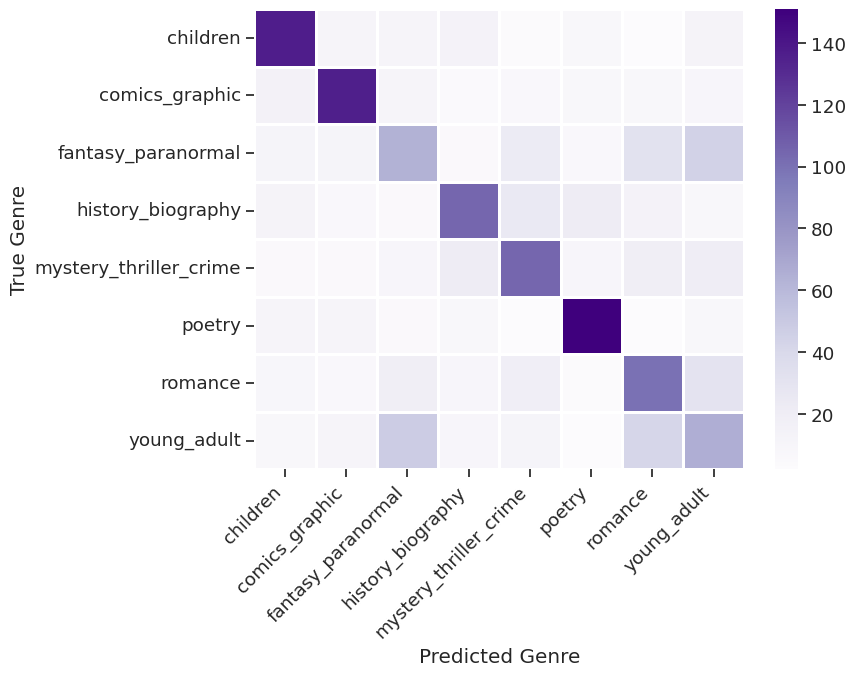

In [ ]:
plt.figure(figsize=(9,7))
sns.set(style='ticks', font_scale=1.2)
sns.heatmap(df_wide, linewidths=1, cmap='Purples')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Looks good! We can see that overall, our model is assigning the correct labels for each genre.

Now, let's remove the diagonal from the plot to highlight the misclassifications.

In [ ]:
genre_classifications_dict = defaultdict(int)
for _true_label, _predicted_label in zip(test_labels, predicted_labels):
  if _true_label != _predicted_label: # Remove the diagonal to highlight misclassifications
    genre_classifications_dict[(_true_label, _predicted_label)] += 1

dicts_to_plot = []
for (_true_genre, _predicted_genre), _count in genre_classifications_dict.items():
  dicts_to_plot.append({'True Genre': _true_genre,
                        'Predicted Genre': _predicted_genre,
                        'Number of Classifications': _count})

df_to_plot = pd.DataFrame(dicts_to_plot)
df_wide = df_to_plot.pivot_table(index='True Genre',
                                 columns='Predicted Genre',
                                 values='Number of Classifications')

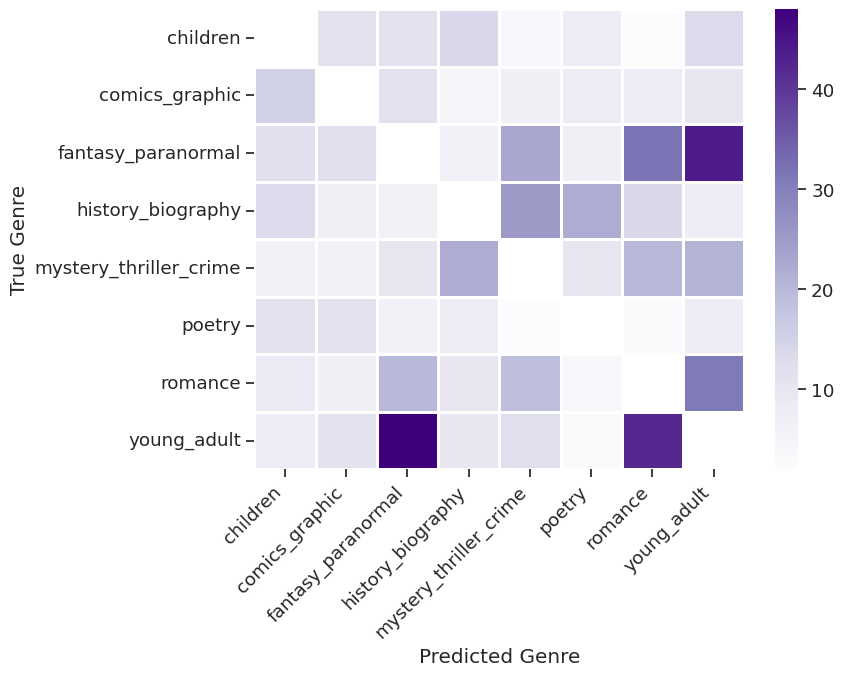

In [ ]:
plt.figure(figsize=(9,7))
sns.set(style='ticks', font_scale=1.2)
sns.heatmap(df_wide, linewidths=1, cmap='Purples')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

There's much more you can do with your own dataset and labels! Classification can be used to apply a small set of labels across a big dataset; to explore misclassifications to better understand users; and much more! We hope you'll use this tutorial in all kinds of creative ways.